### **Student Information**
GitHub ID: carrintio27

Kaggle name: esther

Kaggle private scoreboard snapshot: 78

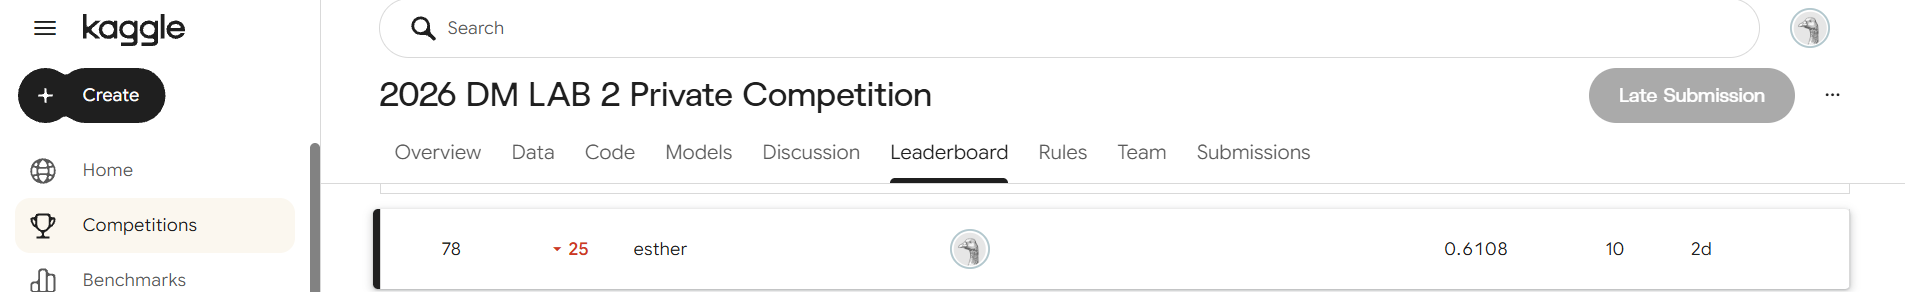

*Your name and student ID are deliberately not asked for here: this notebook goes into your repository, which is public. They belong in the git-ignored `config/.env`, where the other two notebooks read them from, and your NTU COOL submission is what ties the repository link back to you.*

---

# **Instructions**

This lab has **three parts**: exercises in the Master notebook, exercises and an agent conversation in the AgentPipeline notebook, and an internal Kaggle competition documented in this Homework notebook. Together they add up to **100 points**.

**Environment recommendations to solve lab 2:**
- **Part 1 and 2 exercises:** Everything can be run with only CPU.
- **Part 3 exercises:** For the competition you will probably need GPU to train your models, so it is recommended to use Colab or Kaggle if you don't have a laptop with a dedicated GPU.

## **Part 1 (40 pts):**

1. __Main Exercises (35 pts):__ Do the **take home exercises** from Sections: `1. Data Preparation` to `8. Information Retrieval and RAG`, in the DM2026-Lab2-Master Notebook. Total: `13 exercises`. Commit your code and submit the repository link to NTU Cool.

2. **Code Comments (5 pts):** **Tidy up the code in your notebook**. 

## **Part 2 (30 pts):**

1. **Agent Prompt (20 pts):** Interact with the Agent using appropriate prompts to guide it through and complete all the required tasks.

2. **Main Exercises (10 pts):** Do the remaining **take home exercises** from DM2026-Lab2-AgentPipeline Notebook. Total: `3 exercises required`. Commit your code and submit the repository link to NTU Cool.

## **Part 3 (30 pts):**

1. **Kaggle Competition Participation (15 pts):** Submit your predictions to the [Data Mining Class Kaggle Competition](https://www.kaggle.com/t/d99def2e62194b0d8f633267c32e6d1e) by **November 22**. Check Kaggle for the exact closing time. The competition concerns emotion recognition on Twitter; participation points use the Private Leaderboard ranking:
    - If your submission meets or exceeds the **baseline score (F1 score: 0.5)**, and there are no    significant issues with your report or code, you will automatically receive a base score of 5 points of the 15 points.

        The remaining 10 points will be determined by your ranking among participants who meet or exceed the baseline:

        |Ranking  |Additional Points  |
        | --- | --- |
        |Top 10% |+10 |
        |Top 20% |+9 |
        |Top 30% |+8 |
        |Top 40% |+7 |
        |Top 50% |+6 |
        |Top 60% |+5 |
        |Top 70% |+4 |
        |Top 80% |+3 |
        |Top 90% |+2 |
        |<Top 90% |+1 |

    - If your submission does not reach the baseline score, your grade will be lower than 5. The score will range from 0 to 4 points, depending on your Private Leaderboard ranking and the relative performance of students whose submissions are also below the baseline.

2. **Competition Report (15 pts)** A report section to be filled in inside this notebook in Markdown Format, we already provided you with the template below. You need to describe your work developing the model for the competition. The report should include a section describing briefly the following elements: 
* All of your AI prompts and what you decide do use.
* Your preprocessing steps.
* The feature engineering steps.
* Explanation of your model.

[Markdown Guide - Basic Syntax](https://www.markdownguide.org/basic-syntax/)

**`Things to note for Part 3:`**

* **The code used for the competition should be in this Jupyter Notebook File** `DM2026-Lab2-Homework.ipynb`.

* **Push the code used for the competition to your repository**.

* **The code should have a clear separation for the same sections of the report, AI prompts, preprocessing, feature engineering and model explanation. Briefly comment your code for easier understanding, we provide a template at the end of this notebook.**

* Save a screenshot of your Kaggle Private Leaderboard ranking as `pics/pic_ranking.png` and keep the image link in the Student Information cell at the top of this notebook.

The Kaggle competition closes on **November 22**. The three days afterward are for completing this notebook's Markdown report, checking your files, and submitting the lab by **November 25 at 11:59 pm (Wednesday)**.

Push your work to your repository, then submit its link and a ZIP on the corresponding NTU COOL assignment. The ZIP must contain `DM2026-Lab2-Master.ipynb`, `DM2026-Lab2-AgentPipeline.ipynb`, `DM2026-Lab2-Homework.ipynb`, both encrypted logs in `session_logs/`, and `pics/pic_ranking.png`. Name it with your student ID and your name. The two logs are git-ignored, so they are not in your repository and the ZIP is the only copy that reaches us: open it before uploading and check both are inside. If you miss them, you can upload them on NTU COOL until **November 26 at 11:59 pm**. See `README.md` for the exact file paths and setup steps.

---

Next you will find the template report with some simple markdown syntax explanations, use it to structure your content.

You can delete the syntax suggestions after you use them.

---

***

# **Project Report**

**Syntax:** `#` creates the largest heading (H1).

---
**Syntax:** `---` creates a horizontal rule (a separator line).

## 1. Model Development (10 pts Required)

**Syntax:** `##` creates a secondary heading (H2).

**Describe briefly each section, you can add graphs/charts to support your explanations.**

### 1.1 Preprocessing Steps

**Syntax:** `###` creates a tertiary heading (H3).

I started by loading final_posts.json, data_identification.csv, and emotion.csv, then combined them using post_id to match each text with its label and dataset split. In total, there were 3360 labeled training posts and 1440 test posts. Before training, I checked for missing values, duplicate texts, and conflicting labels to make sure the data was consistent. Moreover, I saw that some of the posts had identical texts, so I used stratifiedgroupkfold to split the data into 2687 training and 673 valdiation samples without letting those duplicates overlap. For the transformer model, I kept the original texts and tokenized them with a maximum length of 256 tokens.

**Example Syntax for Content:**
*   **Bold text:** `**text**`
*   *Italic text*: `*text*`
*   Bullet point list:
    * Item 1
    * Item 2

Markdown Syntax to Add Image: `![Description of the Image](./your_local_folder/name_of_the_image.png)`

![Example Markdown Syntax to Add Image](./pics/example_md_img.png)

### 1.2 Feature Engineering Steps

I first tried word tfidf using unigrams and bigrams, then experimented with character tfidf using 3 to 5 character patterns. Since most of the tweets were pretty short and written in different styles, I wanted to see if character patterns could recognize them better. Interestingly, they actually performed better, with the validation macro f1 improving from 0.4434 to 0.5101 using linear svm. After that, I moved on to distilroberta, which used the context of the text rather than just word frequencies. I thought this approach made more sense for emotion classification since the same words could express different emotions depending on how they were used.

### 1.3 Explanation of Your Model

I used a pretrained distilroberta model and fine tuned it to classify the six emotions. I trained it for four epochs with a learning rate of 0.00002, and the best result came from epoch 3 with a validation macro f1 of 0.6022. I also experimented with class weights to help the model recognize less common emotions, but surprisingly, that version performed slightly worse at 0.5985. So instead of relying on just one model, I tried combining their prediction probabilities, using 25% from the original model and 75% from the weighted model. This improved the validation macro f1 to 0.6079. Then, I tried and attempted some postprocessing approaches and experimented with matching duplicate texts and manually reviewing some uncertain predictions. 

Since I went through quite a lot of model versions and experiments, and training each model took a while, I ended up using different environments with gpu access to speed things up and get more submissions in before the deadline. I mainly used kaggle notebooks and google colab, which was also where I got my best result. For this report, I reconstructed the same overall training process into this jupyter notebook, but since the environment and some implementation details were different, rerunning everything didn't exactly produce the very same identical predictions. So disclaimer, there were some differences in the results compared to my original kaggle submissions.

### 1.4 AI Prompts, what and why you decide to use that technique that suggest by AI

I mainly used chatgpt for the competition to help me plan experiment different methods, troubleshoot errors, and figure out what to improve based on the results. Most of my prompts were about comparing different models, improving the validation score, adjusting training settings, and understanding why certain approaches worked better than others.

I asked about using tfidf and svm as simple baselines, then tried fine tuning distilroberta since it could understand the context of the texts better. I also explored class weighting and combining model predictions because they seemed like reasonable ways to improve performance, especially for emotions with fewer samples. Later, I asked chatgpt to review uncertain predictions and suggest corrections, although the results were not always better.

At this point, the submission deadline was getting closer and my leaderboard score was barely improving, so I would say some of my later submissions were purely out of desperation and sheer competitive spirit.

---

**`From here on starts the code section for the competition.`**

---

# **Competition Code**

## 1. Preprocessing Steps

In [2]:
import json
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

#competition data
with open("data/kaggle/final_posts.json", encoding="utf-8") as f:
    posts = pd.DataFrame(json.load(f))

split_info = pd.read_csv("data/kaggle/data_identification.csv")
labels = pd.read_csv("data/kaggle/emotion.csv")

df = posts.merge(split_info, on="post_id", validate="one_to_one")
df = df.merge(labels, on="post_id", how="left", validate="one_to_one")

train_df = df[df["set"] == "train"].copy()
test_df = df[df["set"] == "test"].copy()
print("Training posts:", len(train_df))
print("Test posts:", len(test_df))

#checking duplicates
train_df["text_group"] = train_df["text"].apply(
    lambda text: " ".join(str(text).lower().split())
)

#validation split without duplicate overlap
splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

train_idx, val_idx = next(
    splitter.split(
        train_df,
        train_df["label"],
        groups=train_df["text_group"]
    )
)

train_part = train_df.iloc[train_idx].copy()
val_part = train_df.iloc[val_idx].copy()
print("Model training:", len(train_part))
print("Validation:", len(val_part))

Training posts: 3360
Test posts: 1440
Model training: 2687
Validation: 673


## 2. Feature Engineering Steps

In [3]:
from sklearn.feature_extraction.text import TfidfVectorizer

#word tfidf w unigrams and bigrams
word_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2
)
X_train_word = word_vectorizer.fit_transform(train_part["text"])
X_val_word = word_vectorizer.transform(val_part["text"])

#char tfidf w 3-5 char patterns
char_vectorizer = TfidfVectorizer(
    analyzer="char_wb",
    ngram_range=(3, 5),
    min_df=2
)
X_train_char = char_vectorizer.fit_transform(train_part["text"])
X_val_char = char_vectorizer.transform(val_part["text"])

#feature dimensions output
print("Word tfidf training:", X_train_word.shape)
print("Word tfidf validation:", X_val_word.shape)
print("Character tfidf training:", X_train_char.shape)
print("Character tfidf validation:", X_val_char.shape)

Word tfidf training: (2687, 6008)
Word tfidf validation: (673, 6008)
Character tfidf training: (2687, 23360)
Character tfidf validation: (673, 23360)


## 3. Model Implementation Steps

In [4]:
from sklearn.svm import LinearSVC
from sklearn.metrics import f1_score, accuracy_score

#training svm using word tfidf
word_svm = LinearSVC(C=1.0, random_state=42)
word_svm.fit(X_train_word, train_part["label"])
word_pred = word_svm.predict(X_val_word)

#trainin svm using char tfidf
char_svm = LinearSVC(C=1.0, random_state=42)
char_svm.fit(X_train_char, train_part["label"])
char_pred = char_svm.predict(X_val_char)

#validation results
print("Word tfidf + svm")
print("Macro F1:", round(f1_score(val_part["label"], word_pred, average="macro"), 4))
print("Accuracy:", round(accuracy_score(val_part["label"], word_pred), 4))
print("\nCharacter tfidf + svm")
print("Macro F1:", round(f1_score(val_part["label"], char_pred, average="macro"), 4))
print("Accuracy:", round(accuracy_score(val_part["label"], char_pred), 4))

Word tfidf + svm
Macro F1: 0.4377
Accuracy: 0.4636

Character tfidf + svm
Macro F1: 0.5074
Accuracy: 0.5334


In [5]:
import numpy as np
import torch
from torch.utils.data import Dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    Trainer,
    TrainingArguments,
    DataCollatorWithPadding
)
from sklearn.metrics import f1_score

#model settings
model_name = "j-hartmann/emotion-english-distilroberta-base"
emotion_labels = sorted(train_df["label"].unique())

label_to_id = {name: i for i, name in enumerate(emotion_labels)}
id_to_label = {i: name for name, i in label_to_id.items()}

tokenizer = AutoTokenizer.from_pretrained(model_name)

#prepare tokenized tweets
class EmotionDataset(Dataset):
    def __init__(self, df, has_labels=True):
        self.encodings = tokenizer(
            df["text"].tolist(),
            truncation=True,
            max_length=256
        )
        self.labels = (
            df["label"].map(label_to_id).tolist()
            if has_labels else None
        )

    def __len__(self):
        return len(self.encodings["input_ids"])

    def __getitem__(self, index):
        item = {
            key: values[index]
            for key, values in self.encodings.items()
        }
        if self.labels is not None:
            item["labels"] = self.labels[index]
        return item

train_dataset = EmotionDataset(train_part)
val_dataset = EmotionDataset(val_part)
test_dataset = EmotionDataset(test_df, has_labels=False)

data_collator = DataCollatorWithPadding(tokenizer)

print("Labels:", emotion_labels)
print("Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))
print("GPU:", torch.cuda.is_available())

config.json:   0%|          | 0.00/1.00k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/294 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Labels: ['anger', 'disgust', 'fear', 'joy', 'sadness', 'surprise']
Training: 2687
Validation: 673
Test: 1440
GPU: False


In [6]:
#pretrained model for six emotions
def create_model():
    return AutoModelForSequenceClassification.from_pretrained(
        model_name,
        num_labels=len(emotion_labels),
        id2label=id_to_label,
        label2id=label_to_id,
        ignore_mismatched_sizes=True
    )

#validation macro f1 calc
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)

    return {
        "macro_f1": f1_score(
            labels,
            predictions,
            average="macro"
        )
    }

#training settings
def make_training_args(folder):
    return TrainingArguments(
        output_dir=folder,
        learning_rate=2e-5,
        per_device_train_batch_size=16,
        per_device_eval_batch_size=32,
        num_train_epochs=4,
        eval_strategy="epoch",
        save_strategy="epoch",
        load_best_model_at_end=True,
        metric_for_best_model="macro_f1",
        greater_is_better=True,
        save_total_limit=1,
        report_to="none",
        fp16=torch.cuda.is_available(),
        seed=42
    )

In [7]:
#training original model
standard_trainer = Trainer(
    model=create_model(),
    args=make_training_args("models/v5_standard"),
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)
standard_trainer.train()

#model evaluation
standard_result = standard_trainer.evaluate()
print("Standard model:", standard_result["eval_macro_f1"])

standard_trainer.save_model("models/v5_standard_best")
tokenizer.save_pretrained("models/v5_standard_best")

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.


pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  329MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([6, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
C:\Users\CARRIN SOETIONO\Documents\DM2026Labs\DM2026-Lab2-Exercise\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.123591,0.593036
2,No log,1.141543,0.602896
3,0.948141,1.170750,0.592239
4,0.948141,1.180616,0.594219


... (10 outputs left out)

Training Loss,Validation Loss,Epoch,Macro F1
0.948141,1.141543,4,0.602896


Standard model: 0.6028959327756138


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('models/v5_standard_best\\tokenizer_config.json',
 'models/v5_standard_best\\tokenizer.json')

In [8]:
import torch.nn.functional as F

#class weights calc
counts = train_part["label"].value_counts()
class_weights = torch.tensor(
    [
        (counts.max() / counts[name]) ** 0.5
        for name in emotion_labels
    ],
    dtype=torch.float32
)

#custom trainer with weighted loss
class WeightedTrainer(Trainer):
    def compute_loss(
        self, model, inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):
        labels = inputs["labels"]
        outputs = model(**inputs)

        loss = F.cross_entropy(
            outputs.logits,
            labels,
            weight=class_weights.to(outputs.logits.device)
        )

        return (loss, outputs) if return_outputs else loss

#training weighted model
weighted_trainer = WeightedTrainer(
    model=create_model(),
    args=make_training_args("models/v5_weighted"),
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator,
    processing_class=tokenizer,
    compute_metrics=compute_metrics
)
weighted_trainer.train()

#model evaluation
weighted_result = weighted_trainer.evaluate()
print("Weighted model:", weighted_result["eval_macro_f1"])

weighted_trainer.save_model("models/v5_weighted_best")
tokenizer.save_pretrained("models/v5_weighted_best")

[transformers] You passed `num_labels=6` which is incompatible to the `id2label` map of length `7`.


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: j-hartmann/emotion-english-distilroberta-base
Key                        | Status   |                                                                                       
---------------------------+----------+---------------------------------------------------------------------------------------
classifier.out_proj.weight | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7, 768]) vs model:torch.Size([6, 768])
classifier.out_proj.bias   | MISMATCH | Reinit due to size mismatch - ckpt: torch.Size([7]) vs model:torch.Size([6])          

Notes:
- MISMATCH:	ckpt weights were loaded, but they did not match the original empty weight shapes.
C:\Users\CARRIN SOETIONO\Documents\DM2026Labs\DM2026-Lab2-Exercise\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Epoch,Training Loss,Validation Loss,Macro F1
1,No log,1.156772,0.590418
2,No log,1.167449,0.591932
3,0.970750,1.200477,0.586217
4,0.970750,1.207635,0.593081


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

C:\Users\CARRIN SOETIONO\Documents\DM2026Labs\DM2026-Lab2-Exercise\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


... (6 outputs left out)

Training Loss,Validation Loss,Epoch,Macro F1
0.970750,1.207635,4,0.593081


Weighted model: 0.5930805651180512


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('models/v5_weighted_best\\tokenizer_config.json',
 'models/v5_weighted_best\\tokenizer.json')

In [9]:
from scipy.special import softmax

#validation probabilities
standard_logits = standard_trainer.predict(
    val_dataset
).predictions

weighted_logits = weighted_trainer.predict(
    val_dataset
).predictions

standard_probs = softmax(standard_logits, axis=1)
weighted_probs = softmax(weighted_logits, axis=1)

#combine model probabilities
ensemble_probs = (
    0.25 * standard_probs +
    0.75 * weighted_probs
)
ensemble_predictions = ensemble_probs.argmax(axis=1)
ensemble_labels = [
    id_to_label[i] for i in ensemble_predictions
]

#ensemble evaluation
ensemble_f1 = f1_score(
    val_part["label"],
    ensemble_labels,
    average="macro"
)
print("Ensemble macro F1:", round(ensemble_f1, 4))

C:\Users\CARRIN SOETIONO\Documents\DM2026Labs\DM2026-Lab2-Exercise\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


C:\Users\CARRIN SOETIONO\Documents\DM2026Labs\DM2026-Lab2-Exercise\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Ensemble macro F1: 0.5954


In [13]:
#generate test predictions using the trained models
standard_test = softmax(
    standard_trainer.predict(test_dataset).predictions,
    axis=1
)

weighted_test = softmax(
    weighted_trainer.predict(test_dataset).predictions,
    axis=1
)

#combine prediction probabilities
test_probs = 0.25 * standard_test + 0.75 * weighted_test

test_predictions = [
    id_to_label[i] for i in test_probs.argmax(axis=1)
]

#submission predictions
predictions_df = pd.DataFrame({
    "post_id": test_df["post_id"].values,
    "label": test_predictions
})
sample = pd.read_csv("data/kaggle/sampleSubmission.csv")

submission = sample[["post_id"]].merge(
    predictions_df,
    on="post_id",
    how="left",
    validate="one_to_one"
)
submission = submission.rename(columns={"post_id": "id"})

#check submission
assert submission.shape == (1440, 2)
assert submission["id"].is_unique
assert submission["label"].isin(emotion_labels).all()

#saved predictions
submission.to_csv("local_ensemble_predictions.csv", index=False)
print("Saved:", submission.shape)
print(submission["label"].value_counts())

C:\Users\CARRIN SOETIONO\Documents\DM2026Labs\DM2026-Lab2-Exercise\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Saved: (1440, 2)
label
joy         353
anger       320
sadness     269
surprise    211
disgust     160
fear        127
Name: count, dtype: int64
